In [1]:

# ==========================================
# SYNTECxHUB - PROJECT 1
# CUSTOMER SEGMENTATION USING RFM ANALYSIS
# STEP 1: LOAD THE DATASET
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Alternative CSV download source
url = "https://github.com/dbdmg/data-science-lab/raw/master/datasets/online_retail.csv"

# Load dataset
df = pd.read_csv(url)

# Display first 5 records
print("First 5 Records:")
display(df.head())

# Dataset dimensions
print("\nDataset Shape:")
print(df.shape)

# Dataset information
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nDataset loaded successfully!")


First 5 Records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom



Dataset Shape:
(541909, 8)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate Records:
5268

Dataset loaded successfully!


In [2]:
# ==========================================
# STEP 1: CREATE A BACKUP
# ==========================================

# Keep the original dataset unchanged
df_raw = df.copy()

# Create a working copy for preprocessing
df_clean = df_raw.copy()

print("Original dataset shape:", df_raw.shape)
print("Working dataset shape:", df_clean.shape)

Original dataset shape: (541909, 8)
Working dataset shape: (541909, 8)


**Preprocessing**

In [3]:
# ==========================================
# STEP 2: REMOVE EXACT DUPLICATES
# ==========================================

duplicates_before = df_clean.duplicated().sum()

print("Duplicate records before cleaning:", duplicates_before)

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates()

duplicates_after = df_clean.duplicated().sum()

print("Duplicate records after cleaning:", duplicates_after)
print("Dataset shape after removing duplicates:", df_clean.shape)

Duplicate records before cleaning: 5268
Duplicate records after cleaning: 0
Dataset shape after removing duplicates: (536641, 8)


In [4]:
# ==========================================
# STEP 3: HANDLE MISSING CUSTOMER IDs
# ==========================================

missing_customer_before = df_clean["CustomerID"].isnull().sum()

print("Missing CustomerID before cleaning:",
      missing_customer_before)

# Remove records without customer identification
df_clean = df_clean.dropna(subset=["CustomerID"])

print("Missing CustomerID after cleaning:",
      df_clean["CustomerID"].isnull().sum())

print("Dataset shape:", df_clean.shape)

Missing CustomerID before cleaning: 135037
Missing CustomerID after cleaning: 0
Dataset shape: (401604, 8)


In [5]:
# ==========================================
# STEP 4: CONVERT INVOICE DATE
# ==========================================

# Convert InvoiceDate from text into datetime
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"],
    errors="coerce"
)

# Check invalid dates
print("Invalid InvoiceDate values:",
      df_clean["InvoiceDate"].isnull().sum())

# Remove rows with invalid dates
df_clean = df_clean.dropna(subset=["InvoiceDate"])

print("\nInvoiceDate data type:")
print(df_clean["InvoiceDate"].dtype)

print("\nDate range:")
print("First transaction:", df_clean["InvoiceDate"].min())
print("Last transaction:", df_clean["InvoiceDate"].max())

Invalid InvoiceDate values: 0

InvoiceDate data type:
datetime64[ns]

Date range:
First transaction: 2010-12-01 08:26:00
Last transaction: 2011-12-09 12:50:00


In [6]:
# ==========================================
# STEP 5: HANDLE CANCELLED INVOICES
# ==========================================

# Identify invoice numbers starting with C
cancelled_mask = (
    df_clean["InvoiceNo"]
    .astype(str)
    .str.strip()
    .str.upper()
    .str.startswith("C")
)

print("Cancelled invoice rows:", cancelled_mask.sum())

# Remove cancelled invoice rows
df_clean = df_clean[~cancelled_mask].copy()

print("Dataset shape after removing cancellations:",
      df_clean.shape)

Cancelled invoice rows: 8872
Dataset shape after removing cancellations: (392732, 8)


In [7]:
# ==========================================
# STEP 6: HANDLE INVALID QUANTITIES
# AND UNIT PRICES
# ==========================================

print("Negative quantity rows:",
      (df_clean["Quantity"] < 0).sum())

print("Zero quantity rows:",
      (df_clean["Quantity"] == 0).sum())

print("Zero or negative price rows:",
      (df_clean["UnitPrice"] <= 0).sum())

# Keep only positive purchase quantities
df_clean = df_clean[df_clean["Quantity"] > 0].copy()

# Keep only positive unit prices
df_clean = df_clean[df_clean["UnitPrice"] > 0].copy()

print("\nDataset shape after filtering:")
print(df_clean.shape)

Negative quantity rows: 0
Zero quantity rows: 0
Zero or negative price rows: 40

Dataset shape after filtering:
(392692, 8)


In [8]:
# ==========================================
# STEP 7: CREATE TOTAL PRICE
# ==========================================

# Calculate transaction line value
df_clean["TotalPrice"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

# Display selected columns
display(
    df_clean[
        ["InvoiceNo", "CustomerID", "Quantity",
         "UnitPrice", "TotalPrice"]
    ].head()
)

print("\nTotal transaction value:")
print(df_clean["TotalPrice"].sum())

,InvoiceNo,CustomerID,Quantity,UnitPrice,TotalPrice
0,536365,17850.0,6,2.55,15.30
1,536365,17850.0,6,3.39,20.34
2,536365,17850.0,8,2.75,22.00
3,536365,17850.0,6,3.39,20.34
4,536365,17850.0,6,3.39,20.34



Total transaction value:
8887208.894000001


In [9]:
# ==========================================
# STEP 8: FINAL DATA QUALITY CHECK
# ==========================================

print("FINAL CLEANED DATASET")
print("=" * 40)

print("Original dataset shape:", df_raw.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nDuplicate records:")
print(df_clean.duplicated().sum())

print("\nNegative quantities:")
print((df_clean["Quantity"] < 0).sum())

print("\nInvalid unit prices:")
print((df_clean["UnitPrice"] <= 0).sum())

print("\nUnique customers:")
print(df_clean["CustomerID"].nunique())

print("\nUnique invoices:")
print(df_clean["InvoiceNo"].nunique())

print("\nTotal purchase value:")
print(round(df_clean["TotalPrice"].sum(), 2))

print("\nFinal dataset preview:")
display(df_clean.head())

FINAL CLEANED DATASET
Original dataset shape: (541909, 8)
Cleaned dataset shape: (392692, 9)

Missing values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
TotalPrice     0
dtype: int64

Duplicate records:
0

Negative quantities:
0

Invalid unit prices:
0

Unique customers:
4338

Unique invoices:
18532

Total purchase value:
8887208.89

Final dataset preview:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


**Calculate RFM for every customer**

In [10]:

# ==========================================
# STEP 10: RFM METRIC CALCULATION
# ==========================================

import pandas as pd

# Set the analysis reference date
reference_date = pd.Timestamp("2011-12-10")

# Group transactions by customer and calculate RFM
rfm = df_clean.groupby("CustomerID").agg(
    Recency=("InvoiceDate",
             lambda x: (reference_date - x.max()).days),

    Frequency=("InvoiceNo", "nunique"),

    Monetary=("TotalPrice", "sum")
).reset_index()

# Round monetary values to 2 decimal places
rfm["Monetary"] = rfm["Monetary"].round(2)

# Display the first 10 customers
print("RFM TABLE - FIRST 10 CUSTOMERS")
display(rfm.head(10))

# Check RFM dataset dimensions
print("\nRFM Dataset Shape:", rfm.shape)

# Check summary statistics
print("\nRFM Summary Statistics:")
display(rfm[["Recency", "Frequency", "Monetary"]].describe())


RFM TABLE - FIRST 10 CUSTOMERS


,CustomerID,Recency,Frequency,Monetary
0,12346.0,325,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,18,1,1757.55
4,12350.0,310,1,334.40
5,12352.0,36,8,2506.04
6,12353.0,204,1,89.00
7,12354.0,232,1,1079.40
8,12355.0,214,1,459.40
9,12356.0,22,3,2811.43



RFM Dataset Shape: (4338, 4)

RFM Summary Statistics:


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.00000
mean,92.059474,4.272015,2048.68808
std,100.012264,7.697998,8985.23022
min,0.000000,1.000000,3.75000
25%,17.000000,1.000000,306.48250
50%,50.000000,2.000000,668.57000
75%,141.750000,5.000000,1660.59750
max,373.000000,209.000000,280206.02000


In [11]:

# ==========================================
# STEP 11: RFM VALIDATION
# ==========================================

print("RFM VALIDATION")
print("=" * 40)

print("Total customers:", rfm["CustomerID"].nunique())

print("\nMissing values:")
print(rfm.isnull().sum())

print("\nDuplicate customers:",
      rfm["CustomerID"].duplicated().sum())

print("\nCustomers with zero or negative Recency:",
      (rfm["Recency"] <= 0).sum())

print("\nCustomers with zero Frequency:",
      (rfm["Frequency"] <= 0).sum())

print("\nCustomers with zero or negative Monetary:",
      (rfm["Monetary"] <= 0).sum())


RFM VALIDATION
Total customers: 4338

Missing values:
CustomerID    0
Recency       0
Frequency     0
Monetary      0
dtype: int64

Duplicate customers: 0

Customers with zero or negative Recency: 35

Customers with zero Frequency: 0

Customers with zero or negative Monetary: 0


In [12]:

# ==========================================
# STEP 12: CORRECT RECENCY CALCULATION
# ==========================================

reference_date = pd.Timestamp("2011-12-10")

# Recalculate Recency using calendar dates
recency_corrected = (
    reference_date -
    df_clean.groupby("CustomerID")["InvoiceDate"]
    .max()
    .dt.normalize()
).dt.days

# Update the RFM table
rfm["Recency"] = rfm["CustomerID"].map(recency_corrected)

print("Corrected Recency Summary:")
display(rfm["Recency"].describe())

print("\nCustomers with zero Recency:",
      (rfm["Recency"] == 0).sum())

print("\nCustomers with Recency of 1 day:",
      (rfm["Recency"] == 1).sum())

print("\nUpdated RFM Table:")
display(rfm.head(10))


Corrected Recency Summary:


,Recency
count,4338.000000
mean,93.059474
std,100.012264
min,1.000000
25%,18.000000
50%,51.000000
75%,142.750000
max,374.000000



Customers with zero Recency: 0

Customers with Recency of 1 day: 35

Updated RFM Table:


,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,3,7,4310.00
2,12348.0,76,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,311,1,334.40
5,12352.0,37,8,2506.04
6,12353.0,205,1,89.00
7,12354.0,233,1,1079.40
8,12355.0,215,1,459.40
9,12356.0,23,3,2811.43


**RFM scoring**

In [13]:

# STEP 13: RFM QUANTILE SCORING

# Calculate RFM scores using quintiles
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Combine scores
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

# Display results
display(rfm.head(10))

print("\nRFM Score Summary:")
display(rfm[["R_Score", "F_Score", "M_Score"]].describe())

print("\nNumber of customers in each score:")
for col in ["R_Score", "F_Score", "M_Score"]:
    print(f"\n{col}")
    print(rfm[col].value_counts().sort_index())


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,12346.0,326,1,77183.60,1,1,5,115
1,12347.0,3,7,4310.00,5,5,5,555
2,12348.0,76,4,1797.24,2,4,4,244
3,12349.0,19,1,1757.55,4,1,4,414
4,12350.0,311,1,334.40,1,1,2,112
5,12352.0,37,8,2506.04,3,5,5,355
6,12353.0,205,1,89.00,1,1,1,111
7,12354.0,233,1,1079.40,1,1,4,114
8,12355.0,215,1,459.40,1,1,2,112
9,12356.0,23,3,2811.43,4,3,5,435



RFM Score Summary:


,R_Score,F_Score,M_Score
count,4338.00000,4338.00000,4338.00000
mean,3.00000,3.00000,3.00000
std,1.41454,1.41454,1.41454
min,1.00000,1.00000,1.00000
25%,2.00000,2.00000,2.00000
50%,3.00000,3.00000,3.00000
75%,4.00000,4.00000,4.00000
max,5.00000,5.00000,5.00000



Number of customers in each score:

R_Score
R_Score
1    868
2    867
3    868
4    867
5    868
Name: count, dtype: int64

F_Score
F_Score
1    868
2    867
3    868
4    867
5    868
Name: count, dtype: int64

M_Score
M_Score
1    868
2    867
3    868
4    867
5    868
Name: count, dtype: int64


In [14]:

# STEP 14: CUSTOMER SEGMENTATION

def segment_customer(row):

    r = row["R_Score"]
    f = row["F_Score"]
    m = row["M_Score"]

    # Best customers: recent, frequent and high spending
    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"

    # Frequent customers with good spending
    elif r >= 3 and f >= 4:
        return "Loyal Customers"

    # Recent customers with potential to become loyal
    elif r >= 4 and f <= 2:
        return "New / Promising Customers"

    # Previously valuable customers who have not purchased recently
    elif r <= 2 and f >= 3 and m >= 3:
        return "At-Risk Customers"

    # Customers with low recency, frequency and spending
    elif r <= 2 and f <= 2 and m <= 2:
        return "Hibernating Customers"

    # Remaining customers
    else:
        return "Other Customers"


# Apply segmentation
rfm["Customer_Segment"] = rfm.apply(
    segment_customer, axis=1
)

# Display sample
display(rfm.head(10))

# Count customers in each segment
segment_summary = (
    rfm["Customer_Segment"]
    .value_counts()
    .reset_index()
)

segment_summary.columns = [
    "Customer_Segment",
    "Customer_Count"
]

segment_summary["Percentage"] = (
    segment_summary["Customer_Count"] /
    len(rfm) * 100
).round(2)

print("Customer Segment Summary:")
display(segment_summary)


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Customer_Segment
0,12346.0,326,1,77183.60,1,1,5,115,Other Customers
1,12347.0,3,7,4310.00,5,5,5,555,Champions
2,12348.0,76,4,1797.24,2,4,4,244,At-Risk Customers
3,12349.0,19,1,1757.55,4,1,4,414,New / Promising Customers
4,12350.0,311,1,334.40,1,1,2,112,Hibernating Customers
5,12352.0,37,8,2506.04,3,5,5,355,Loyal Customers
6,12353.0,205,1,89.00,1,1,1,111,Hibernating Customers
7,12354.0,233,1,1079.40,1,1,4,114,Other Customers
8,12355.0,215,1,459.40,1,1,2,112,Hibernating Customers
9,12356.0,23,3,2811.43,4,3,5,435,Other Customers


Customer Segment Summary:


,Customer_Segment,Customer_Count,Percentage
0,Other Customers,1293,29.81
1,Champions,941,21.69
2,Hibernating Customers,824,18.99
3,Loyal Customers,504,11.62
4,At-Risk Customers,466,10.74
5,New / Promising Customers,310,7.15


In [15]:

# STEP 15: CUSTOMER SEGMENT BEHAVIOUR ANALYSIS

segment_analysis = (
    rfm.groupby("Customer_Segment")
    .agg(
        Customer_Count=("CustomerID", "count"),
        Avg_Recency=("Recency", "mean"),
        Median_Recency=("Recency", "median"),
        Avg_Frequency=("Frequency", "mean"),
        Median_Frequency=("Frequency", "median"),
        Avg_Monetary=("Monetary", "mean"),
        Median_Monetary=("Monetary", "median"),
        Total_Revenue=("Monetary", "sum")
    )
    .round(2)
    .sort_values("Customer_Count", ascending=False)
    .reset_index()
)

# Calculate each segment's contribution to total revenue
segment_analysis["Revenue_Percentage"] = (
    segment_analysis["Total_Revenue"] /
    rfm["Monetary"].sum() * 100
).round(2)

display(segment_analysis)

print("Total customers:", rfm["CustomerID"].nunique())
print("Total revenue: £", round(rfm["Monetary"].sum(), 2))


,Customer_Segment,Customer_Count,Avg_Recency,Median_Recency,Avg_Frequency,Median_Frequency,Avg_Monetary,Median_Monetary,Total_Revenue,Revenue_Percentage
0,Other Customers,1293,87.85,58.0,1.84,2.0,879.00,496.21,1136547.73,12.79
1,Champions,941,12.98,11.0,11.21,7.0,6101.93,2656.13,5741913.58,64.61
2,Hibernating Customers,824,228.09,236.5,1.04,1.0,228.66,208.50,188415.28,2.12
3,Loyal Customers,504,37.37,38.0,5.12,4.0,1821.52,915.63,918045.60,10.33
4,At-Risk Customers,466,140.18,120.0,3.82,3.0,1644.91,1045.44,766529.58,8.63
5,New / Promising Customers,310,18.67,19.0,1.25,1.0,437.93,308.61,135757.12,1.53


Total customers: 4338
Total revenue: £ 8887208.89


In [16]:

# STEP 16: INVESTIGATE OTHER CUSTOMERS

other_customers = rfm[
    rfm["Customer_Segment"] == "Other Customers"
].copy()

# Count different RFM score combinations
other_rfm_patterns = (
    other_customers
    .groupby(["R_Score", "F_Score", "M_Score"])
    .agg(
        Customer_Count=("CustomerID", "count"),
        Avg_Recency=("Recency", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Monetary=("Monetary", "mean"),
        Total_Revenue=("Monetary", "sum")
    )
    .round(2)
    .reset_index()
    .sort_values("Customer_Count", ascending=False)
)

other_rfm_patterns["Percentage"] = (
    other_rfm_patterns["Customer_Count"] /
    len(other_customers) * 100
).round(2)

display(other_rfm_patterns.head(20))

print("Total Other Customers:", len(other_customers))
print("Unique RFM combinations:", len(other_rfm_patterns))


,R_Score,F_Score,M_Score,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue,Percentage
27,3,2,1,69,52.68,1.09,157.89,10894.56,5.34
22,3,1,1,67,52.94,1.00,160.96,10784.27,5.18
34,3,3,3,67,53.10,2.27,680.91,45621.29,5.18
39,4,3,3,62,24.48,2.29,664.52,41200.13,4.80
23,3,1,2,59,53.71,1.00,371.00,21888.76,4.56
18,2,3,2,56,122.29,2.30,372.22,20844.08,4.33
7,1,3,2,56,246.27,2.18,351.34,19674.89,4.33
28,3,2,2,56,54.21,1.20,348.54,19518.03,4.33
14,2,2,3,52,108.92,1.58,659.90,34314.66,4.02
33,3,3,2,49,51.02,2.10,373.37,18294.94,3.79


Total Other Customers: 1293
Unique RFM combinations: 47


In [17]:

# STEP 17: REFINED CUSTOMER SEGMENTATION

def refined_segment_customer(row):

    r = row["R_Score"]
    f = row["F_Score"]
    m = row["M_Score"]

    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"

    elif r >= 3 and f >= 4:
        return "Loyal Customers"

    elif r >= 3 and f <= 3 and m >= 4:
        return "Potential High-Value Customers"

    elif r >= 4 and f == 3:
        return "Potential Loyalists"

    elif r >= 4 and f <= 2:
        return "New / Promising Customers"

    elif r <= 2 and f >= 3 and m >= 3:
        return "At-Risk Customers"

    elif r <= 2 and f <= 2 and m <= 2:
        return "Hibernating Customers"

    else:
        return "Other Customers"


# Update customer segments
rfm["Customer_Segment"] = rfm.apply(
    refined_segment_customer, axis=1
)

# Calculate updated segment counts
refined_summary = (
    rfm["Customer_Segment"]
    .value_counts()
    .reset_index()
)

refined_summary.columns = [
    "Customer_Segment",
    "Customer_Count"
]

refined_summary["Percentage"] = (
    refined_summary["Customer_Count"] /
    len(rfm) * 100
).round(2)

print("Refined Customer Segment Summary:")
display(refined_summary)

print("Total customers:", rfm["CustomerID"].nunique())
print("Total segment customers:", refined_summary["Customer_Count"].sum())


Refined Customer Segment Summary:


,Customer_Segment,Customer_Count,Percentage
0,Champions,941,21.69
1,Other Customers,897,20.68
2,Hibernating Customers,824,18.99
3,Loyal Customers,504,11.62
4,At-Risk Customers,466,10.74
5,New / Promising Customers,280,6.45
6,Potential Loyalists,222,5.12
7,Potential High-Value Customers,204,4.70


Total customers: 4338
Total segment customers: 4338


In [18]:

# STEP 18: REFINED SEGMENT PERFORMANCE ANALYSIS

refined_analysis = (
    rfm.groupby("Customer_Segment")
    .agg(
        Customer_Count=("CustomerID", "count"),
        Avg_Recency=("Recency", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Monetary=("Monetary", "mean"),
        Median_Monetary=("Monetary", "median"),
        Total_Revenue=("Monetary", "sum")
    )
    .round(2)
    .reset_index()
)

# Calculate customer and revenue percentages
refined_analysis["Customer_Percentage"] = (
    refined_analysis["Customer_Count"] /
    len(rfm) * 100
).round(2)

refined_analysis["Revenue_Percentage"] = (
    refined_analysis["Total_Revenue"] /
    rfm["Monetary"].sum() * 100
).round(2)

# Sort by revenue contribution
refined_analysis = refined_analysis.sort_values(
    "Total_Revenue", ascending=False
)

display(refined_analysis)

print("Total customers:", refined_analysis["Customer_Count"].sum())
print("Total revenue: £", round(rfm["Monetary"].sum(), 2))
print(
    "Revenue contribution:",
    refined_analysis["Revenue_Percentage"].sum(),
    "%"
)



,Customer_Segment,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Median_Monetary,Total_Revenue,Customer_Percentage,Revenue_Percentage
1,Champions,941,12.98,11.21,6101.93,2656.13,5741913.58,21.69,64.61
3,Loyal Customers,504,37.37,5.12,1821.52,915.63,918045.60,11.62,10.33
0,At-Risk Customers,466,140.18,3.82,1644.91,1045.44,766529.58,10.74,8.63
5,Other Customers,897,115.61,1.63,634.84,422.58,569453.56,20.68,6.41
6,Potential High-Value Customers,204,33.12,2.32,2490.30,1276.53,508020.75,4.70,5.72
2,Hibernating Customers,824,228.09,1.04,228.66,208.50,188415.28,18.99,2.12
7,Potential Loyalists,222,16.41,2.22,482.78,477.86,107176.12,5.12,1.21
4,New / Promising Customers,280,18.85,1.19,313.05,273.88,87654.42,6.45,0.99


Total customers: 4338
Total revenue: £ 8887208.89
Revenue contribution: 100.02000000000001 %


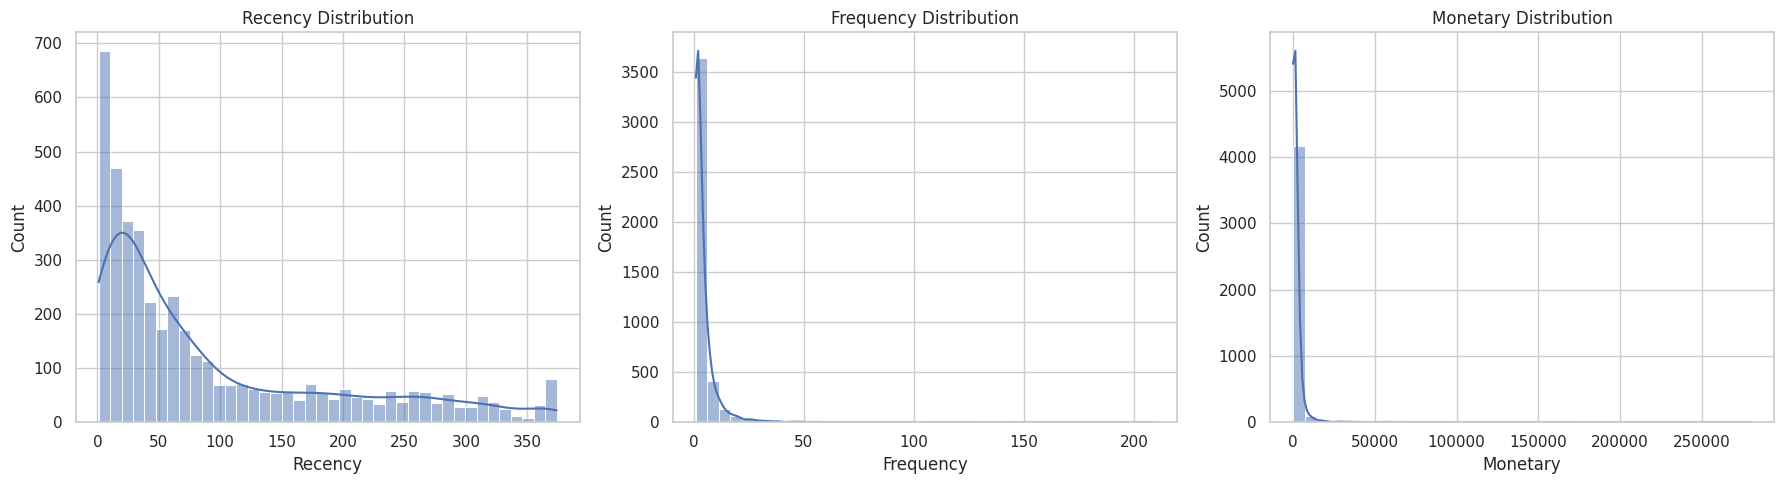

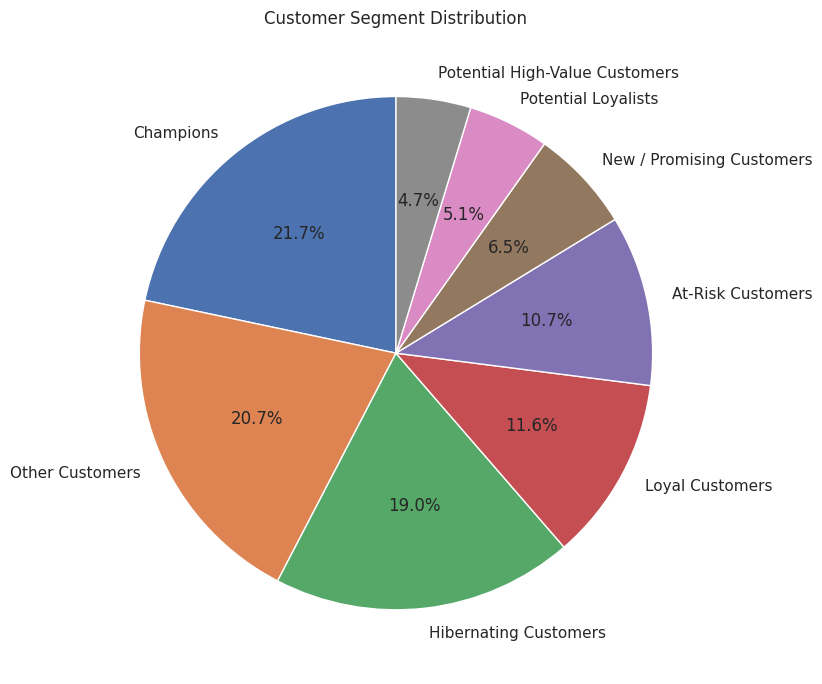

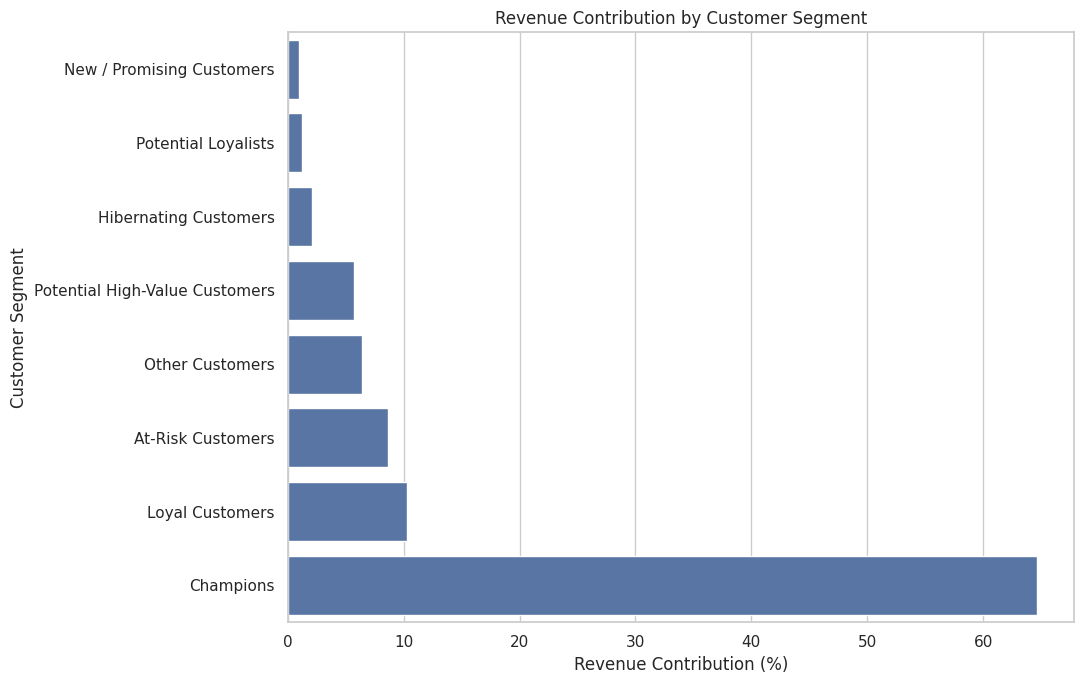

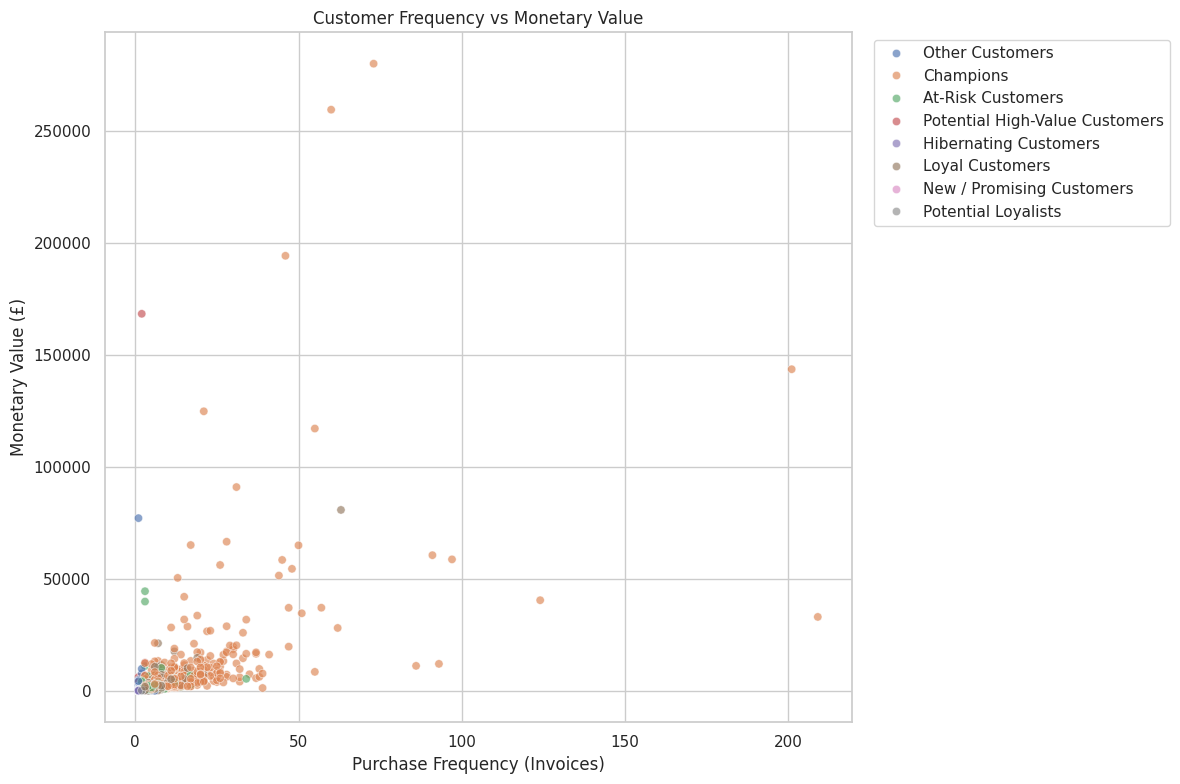

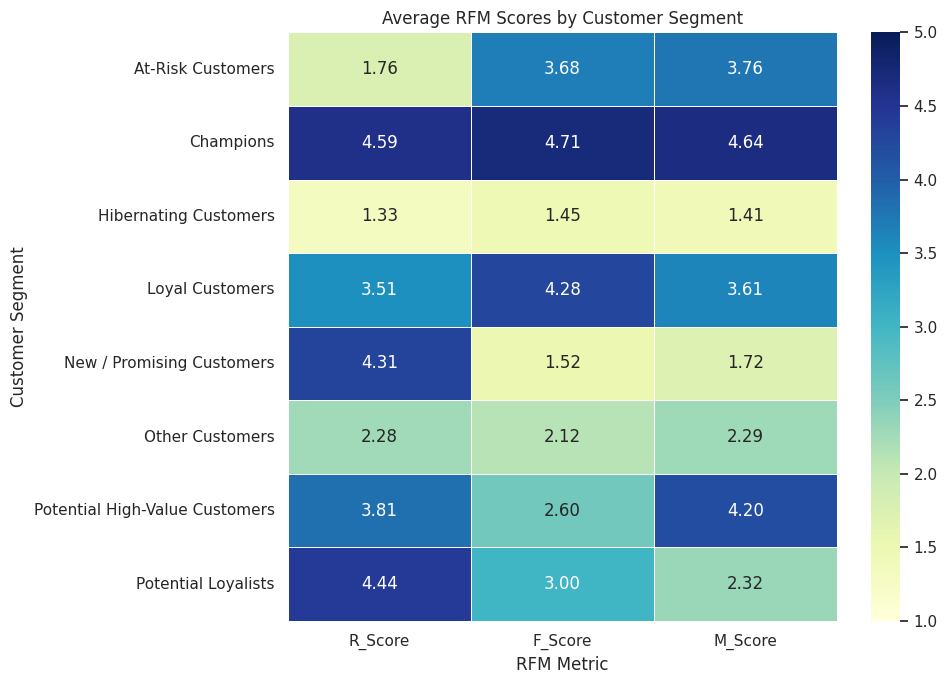

All five visualisations saved successfully!


In [19]:

# STEP 19: FINAL CUSTOMER SEGMENTATION VISUALISATIONS

import matplotlib.pyplot as plt
import seaborn as sns
import os

# Create output folder
os.makedirs("rfm_visualisations", exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")

# 1. RFM DISTRIBUTIONS
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics = ["Recency", "Frequency", "Monetary"]

for ax, metric in zip(axes, metrics):
    sns.histplot(
        data=rfm,
        x=metric,
        bins=40,
        kde=True,
        ax=ax
    )
    ax.set_title(f"{metric} Distribution")
    ax.set_xlabel(metric)

plt.tight_layout()
plt.savefig(
    "rfm_visualisations/01_rfm_distributions.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# 2. CUSTOMER SEGMENT DISTRIBUTION
segment_order = (
    rfm["Customer_Segment"]
    .value_counts()
    .index
)

plt.figure(figsize=(10, 7))

plt.pie(
    rfm["Customer_Segment"].value_counts().reindex(segment_order),
    labels=segment_order,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Customer Segment Distribution")
plt.tight_layout()
plt.savefig(
    "rfm_visualisations/02_segment_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# 3. REVENUE CONTRIBUTION
revenue_plot = refined_analysis.sort_values(
    "Revenue_Percentage", ascending=True
)

plt.figure(figsize=(11, 7))

sns.barplot(
    data=revenue_plot,
    x="Revenue_Percentage",
    y="Customer_Segment"
)

plt.title("Revenue Contribution by Customer Segment")
plt.xlabel("Revenue Contribution (%)")
plt.ylabel("Customer Segment")

plt.tight_layout()
plt.savefig(
    "rfm_visualisations/03_revenue_contribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# 4. CUSTOMER BEHAVIOUR COMPARISON
plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="Customer_Segment",
    alpha=0.65
)

plt.title("Customer Frequency vs Monetary Value")
plt.xlabel("Purchase Frequency (Invoices)")
plt.ylabel("Monetary Value (£)")
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.savefig(
    "rfm_visualisations/04_customer_behaviour.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# 5. AVERAGE RFM SCORE HEATMAP
score_summary = (
    rfm.groupby("Customer_Segment")[
        ["R_Score", "F_Score", "M_Score"]
    ]
    .mean()
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    score_summary,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5,
    vmin=1,
    vmax=5
)

plt.title("Average RFM Scores by Customer Segment")
plt.xlabel("RFM Metric")
plt.ylabel("Customer Segment")

plt.tight_layout()
plt.savefig(
    "rfm_visualisations/05_rfm_score_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


print("All five visualisations saved successfully!")


In [20]:

# STEP 20: DOWNLOAD ALL VISUALISATIONS

import shutil
from google.colab import files
import os

# Check whether the visualisation folder exists
folder_path = "rfm_visualisations"

if os.path.exists(folder_path):

    # Create a ZIP file containing all images
    shutil.make_archive(
        "RFM_Customer_Segmentation_Graphs",
        "zip",
        folder_path
    )

    # Download the ZIP file
    files.download("RFM_Customer_Segmentation_Graphs.zip")

    print("All visualisations are ready for download!")

else:
    print("Visualisation folder not found. Run Step 19 first.")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

All visualisations are ready for download!


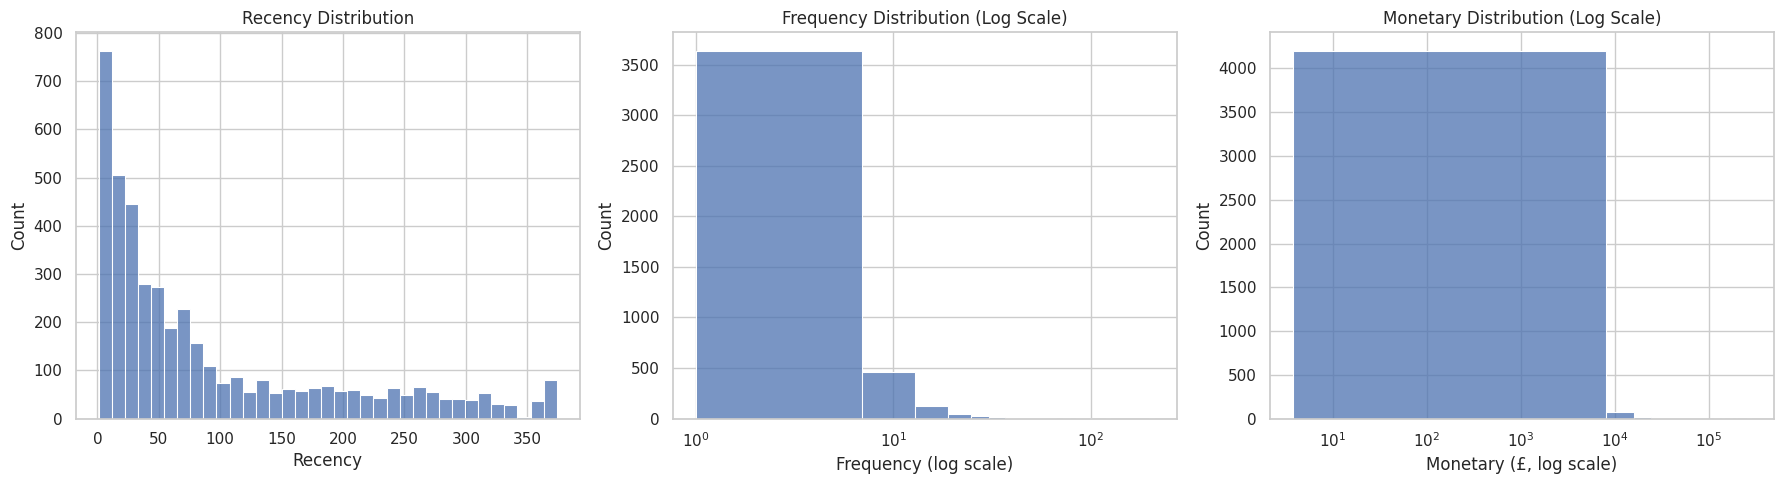

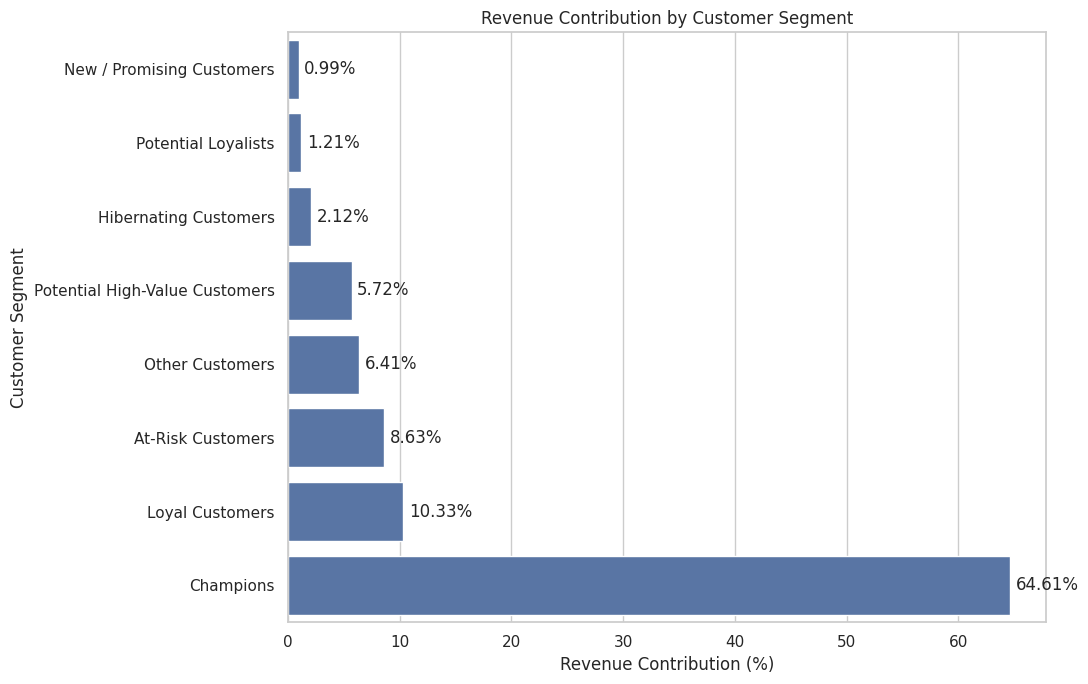

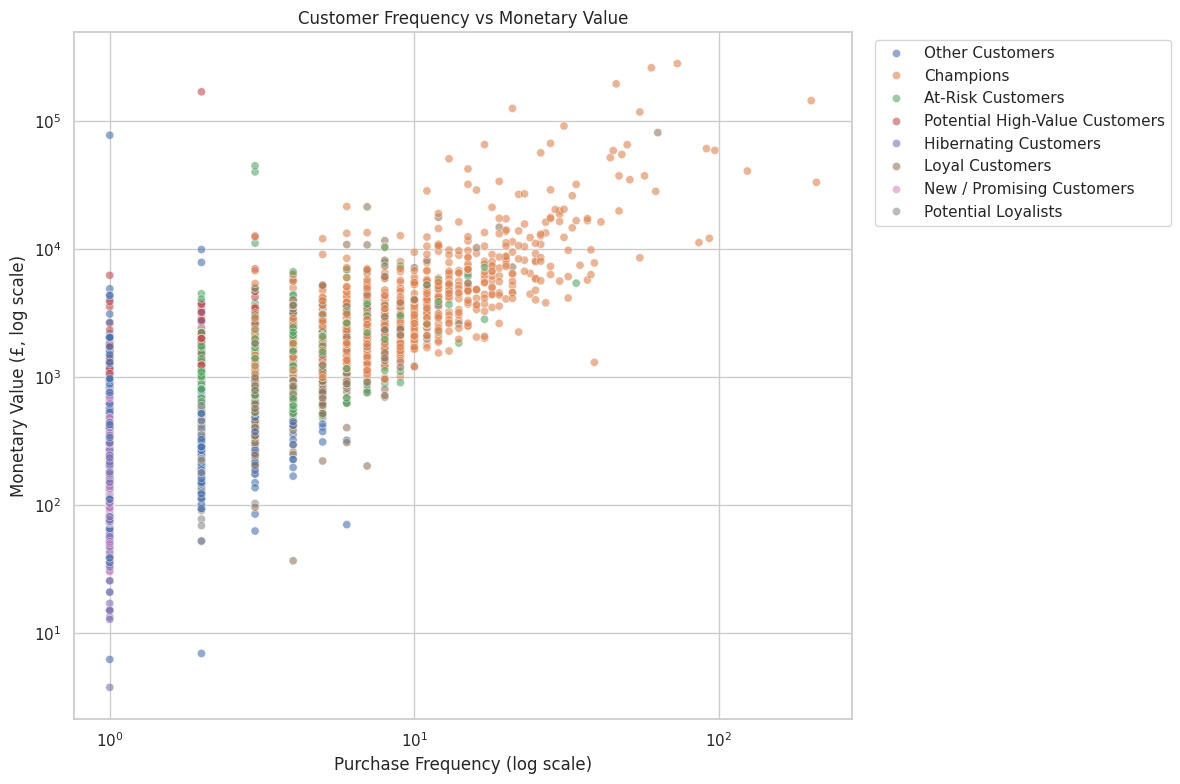

Improved visualisations saved successfully!


In [21]:

# IMPROVED VISUALISATIONS

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style="whitegrid")

# 1. Improved RFM distributions
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(rfm["Recency"], bins=35, ax=axes[0])
axes[0].set_title("Recency Distribution")

sns.histplot(rfm["Frequency"], bins=35, ax=axes[1])
axes[1].set_xscale("log")
axes[1].set_title("Frequency Distribution (Log Scale)")
axes[1].set_xlabel("Frequency (log scale)")

sns.histplot(rfm["Monetary"], bins=35, ax=axes[2])
axes[2].set_xscale("log")
axes[2].set_title("Monetary Distribution (Log Scale)")
axes[2].set_xlabel("Monetary (£, log scale)")

plt.tight_layout()
plt.savefig(
    "rfm_visualisations/01_improved_rfm_distributions.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# 2. Improved revenue contribution with labels
revenue_plot = refined_analysis.sort_values(
    "Revenue_Percentage", ascending=True
)

plt.figure(figsize=(11, 7))

ax = sns.barplot(
    data=revenue_plot,
    x="Revenue_Percentage",
    y="Customer_Segment"
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=4
    )

plt.title("Revenue Contribution by Customer Segment")
plt.xlabel("Revenue Contribution (%)")
plt.ylabel("Customer Segment")
plt.tight_layout()

plt.savefig(
    "rfm_visualisations/03_improved_revenue_contribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# 3. Improved customer behaviour scatter plot
plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="Customer_Segment",
    alpha=0.6,
    s=35
)

plt.xscale("log")
plt.yscale("log")

plt.title("Customer Frequency vs Monetary Value")
plt.xlabel("Purchase Frequency (log scale)")
plt.ylabel("Monetary Value (£, log scale)")

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    "rfm_visualisations/04_improved_customer_behaviour.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Improved visualisations saved successfully!")


In [22]:

import os
import shutil
from google.colab import files

# Improved graph filenames
improved_files = [
    "01_improved_rfm_distributions.png",
    "03_improved_revenue_contribution.png",
    "04_improved_customer_behaviour.png"
]

folder = "rfm_visualisations"

# Check that all three images exist
missing = [
    f for f in improved_files
    if not os.path.exists(os.path.join(folder, f))
]

if missing:
    print("Please run the improved visualisation code first.")
    print("Missing files:", missing)

else:
    # Create a folder containing only improved graphs
    os.makedirs("Improved_RFM_Graphs", exist_ok=True)

    for f in improved_files:
        shutil.copy(
            os.path.join(folder, f),
            os.path.join("Improved_RFM_Graphs", f)
        )

    # Create ZIP file
    shutil.make_archive(
        "Improved_RFM_Graphs",
        "zip",
        "Improved_RFM_Graphs"
    )

    # Download
    files.download("Improved_RFM_Graphs.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>